**Nota:** A lo largo de este cuaderno,al igual que en el aterior cuaderno, cualquier referencia a **v2** hace alusión al **sistema basado exclusivamente en un LLM (LLM puro)**, mientras que cualquier referencia a **v3** corresponde al **sistema híbrido**. Esta nomenclatura se mantiene porque ambas versiones fueron desarrolladas originalmente con esos identificadores y, por motivos de consistencia con el código, los experimentos y la documentación generada durante el desarrollo, dichas referencias se han conservado en este notebook.

In [1]:
import sys
sys.path.append("../src")

from sistema_llm_puro import (
    cargar_datos, get_llm, ranking_50,
    TICKERS, NOMBRES, PERFILES
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import time
import yfinance as yf
%matplotlib inline

# Cargamos datos y LLM
llm   = get_llm()
datos = cargar_datos()

precios = pd.DataFrame({t: datos[t]["Close"] for t in TICKERS})
precios = precios.dropna()

print(f"Periodo: {precios.index[0].date()} -> {precios.index[-1].date()}")
print(f"Sesiones: {len(precios)}")

C:\Users\Ferpo\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Datos cargados: 50/50 tickers
Periodo: 2019-01-02 -> 2024-12-30
Sesiones: 1509


In [23]:
def calcular_indicadores_mes(ticker, df_hasta_fecha):
    try:
        delta    = df_hasta_fecha["Close"].diff()
        ganancia = delta.clip(lower=0).rolling(14).mean()
        perdida  = (-delta.clip(upper=0)).rolling(14).mean()
        rsi      = 100 - (100 / (1 + ganancia / perdida))
        rsi_val  = round(float(rsi.iloc[-1]), 1)

        ema12       = df_hasta_fecha["Close"].ewm(span=12, adjust=False).mean()
        ema26       = df_hasta_fecha["Close"].ewm(span=26, adjust=False).mean()
        macd        = ema12 - ema26
        macd_signal = macd.ewm(span=9, adjust=False).mean()
        macd_val    = round(float(macd.iloc[-1]), 4)
        signal_val  = round(float(macd_signal.iloc[-1]), 4)

        sma20    = df_hasta_fecha["Close"].rolling(20).mean()
        std20    = df_hasta_fecha["Close"].rolling(20).std()
        bb_upper = sma20 + 2 * std20
        bb_lower = sma20 - 2 * std20
        bb_pct   = (df_hasta_fecha["Close"] - bb_lower) / (bb_upper - bb_lower)
        bb_val   = round(float(bb_pct.iloc[-1]), 2)

        precio = round(float(df_hasta_fecha["Close"].iloc[-1]), 2)
        return f"{ticker}: Precio:${precio} RSI:{rsi_val} MACD:{macd_val} Señal:{signal_val} BB:{bb_val}"
    except:
        return f"{ticker}: sin datos"

def generar_señales_mensuales(datos, llm, perfiles=["conservador", "moderado", "agresivo"]):
    from langchain_ollama import ChatOllama
    from sistema_llm_puro import SeñalBatch

    llm_batch = llm.with_structured_output(SeñalBatch)
    os.makedirs("../results", exist_ok=True)

    años  = range(2019, 2025)
    meses = range(1, 13)

    for perfil in perfiles:
        ruta_csv = f"../results/señales_mensuales_{perfil}.csv"

        if os.path.exists(ruta_csv):
            df_existente = pd.read_csv(ruta_csv)
            meses_hechos = set(zip(df_existente["año"], df_existente["mes"]))
            print(f"[{perfil}] Retomando desde donde se quedo — {len(meses_hechos)} meses ya procesados")
        else:
            meses_hechos = set()
            print(f"[{perfil}] Empezando desde cero")

        inicio_perfil = time.time()

        for año in años:
            for mes in meses:
                if (año, mes) in meses_hechos:
                    continue

                fecha_fin = pd.Period(f"{año}-{mes:02d}").end_time.strftime("%Y-%m-%d")
                grupos    = [TICKERS[i:i+5] for i in range(0, len(TICKERS), 5)]
                señales_mes = []

                inicio_mes = time.time()
                print(f"  [{perfil}] {año}-{mes:02d}", end=" ")

                for grupo in grupos:
                    datos_grupo = []
                    for ticker in grupo:
                        df_hasta = datos[ticker].loc[:fecha_fin]
                        if len(df_hasta) >= 20:
                            datos_grupo.append(calcular_indicadores_mes(ticker, df_hasta))

                    if not datos_grupo:
                        continue

                    prompt = f"""Perfil del inversor: {PERFILES[perfil]['descripcion']}
Analiza estas acciones con datos hasta {fecha_fin} y da una señal para cada una:
{chr(10).join(datos_grupo)}"""

                    try:
                        resultado = llm_batch.invoke(prompt)
                        for s in resultado.señales:
                            señales_mes.append({
                                "año":           año,
                                "mes":           mes,
                                "fecha":         fecha_fin,
                                "ticker":        s.ticker,
                                "decision":      s.decision,
                                "confianza":     s.confianza,
                                "justificacion": s.justificacion,
                                "perfil":        perfil,
                            })
                    except Exception as e:
                        print(f"Error: {e}")

                    time.sleep(10)

                if señales_mes:
                    df_mes = pd.DataFrame(señales_mes)
                    df_mes.to_csv(ruta_csv, mode="a",
                                  header=not os.path.exists(ruta_csv) or os.path.getsize(ruta_csv) == 0,
                                  index=False)

                tiempo_mes = round(time.time() - inicio_mes, 1)
                print(f"→ {len(señales_mes)} señales en {tiempo_mes}s")

        tiempo_perfil = round((time.time() - inicio_perfil) / 3600, 2)
        print(f"\n[{perfil}] Completado en {tiempo_perfil} horas")

    print("\nGeneracion de señales mensuales completada")

print("Funcion generar_señales_mensuales definida")
print("Cuando quieras ejecutar el backtesting completo llama a:")
print("  generar_señales_mensuales(datos, llm)")

Funcion generar_señales_mensuales definida
Cuando quieras ejecutar el backtesting completo llama a:
  generar_señales_mensuales(datos, llm)


In [3]:
def calcular_señales_cuantitativas(datos, modo="moderado"):
    señales = pd.DataFrame(index=precios.index)

    for ticker in TICKERS:
        df = datos[ticker].copy()

        delta    = df["Close"].diff()
        ganancia = delta.clip(lower=0).rolling(14).mean()
        perdida  = (-delta.clip(upper=0)).rolling(14).mean()
        rsi      = 100 - (100 / (1 + ganancia / perdida))

        ema12       = df["Close"].ewm(span=12, adjust=False).mean()
        ema26       = df["Close"].ewm(span=26, adjust=False).mean()
        macd        = ema12 - ema26
        macd_signal = macd.ewm(span=9, adjust=False).mean()

        señal_rsi  = pd.Series(0, index=df.index)
        señal_macd = pd.Series(0, index=df.index)

        señal_rsi[rsi < 35]  =  1
        señal_rsi[rsi > 65]  = -1
        señal_macd[macd > macd_signal] =  1
        señal_macd[macd < macd_signal] = -1

        if modo == "conservador":
            combinada = pd.Series(0, index=df.index)
            combinada[(señal_rsi == 1)  & (señal_macd == 1)]  =  1
            combinada[(señal_rsi == -1) & (señal_macd == -1)] = -1
        elif modo == "agresivo":
            combinada = pd.Series(0, index=df.index)
            combinada[(señal_rsi == 1)  | (señal_macd == 1)]  =  1
            combinada[(señal_rsi == -1) | (señal_macd == -1)] = -1
        else:
            combinada = señal_macd

        señales[ticker] = combinada.reindex(precios.index)

    return señales.fillna(0)


def backtesting_diario(precios, señales_matriz, perfil, capital_inicial=100_000):
    capital    = capital_inicial
    posiciones = {}
    historial  = []
    comision   = 0.001
    max_pos    = PERFILES[perfil]["max_posiciones"]

    for fecha in precios.index:
        precios_hoy = precios.loc[fecha]
        señales_hoy = señales_matriz.loc[fecha] if fecha in señales_matriz.index else pd.Series(0, index=TICKERS)

        for ticker in list(posiciones.keys()):
            if señales_hoy.get(ticker, 0) <= 0:
                precio   = precios_hoy[ticker]
                shares   = posiciones[ticker]
                capital += shares * precio * (1 - comision)
                del posiciones[ticker]

        tickers_buy  = [t for t in TICKERS if señales_hoy.get(t, 0) == 1 and t not in posiciones]
        slots_libres = max_pos - len(posiciones)

        for ticker in tickers_buy[:slots_libres]:
            precio          = precios_hoy[ticker]
            capital_por_pos = capital / (slots_libres + 1)
            if capital_por_pos > precio:
                shares = int(capital_por_pos / precio)
                coste  = shares * precio * (1 + comision)
                if coste <= capital:
                    capital -= coste
                    posiciones[ticker] = shares

        valor_pos = sum(
            posiciones[t] * precios_hoy[t]
            for t in posiciones
            if t in precios_hoy and not pd.isna(precios_hoy[t])
        )
        historial.append({
            "fecha": fecha,
            "total": capital + valor_pos,
        })

    return pd.DataFrame(historial).set_index("fecha")


def backtesting(precios, señales_df, perfil, capital_inicial=100_000):
    capital      = capital_inicial
    posiciones   = {}
    historial    = []
    comision     = 0.001
    max_pos      = PERFILES[perfil]["max_posiciones"]
    conf_minima  = PERFILES[perfil]["confianza_minima"]

    señales_perfil = señales_df[
        (señales_df["perfil"] == perfil) &
        (señales_df["confianza"] >= conf_minima)
    ].copy()
    señales_perfil["fecha"] = pd.to_datetime(señales_perfil["fecha"])

    for fecha in precios.index:
        precios_hoy = precios.loc[fecha]

        señales_hoy = señales_perfil[
            (señales_perfil["fecha"].dt.year  == fecha.year) &
            (señales_perfil["fecha"].dt.month == fecha.month)
        ]

        for ticker in list(posiciones.keys()):
            señal_ticker = señales_hoy[señales_hoy["ticker"] == ticker]
            if señal_ticker.empty or señal_ticker.iloc[0]["decision"] != "BUY":
                if ticker in precios_hoy and not pd.isna(precios_hoy[ticker]):
                    precio   = precios_hoy[ticker]
                    shares   = posiciones[ticker]
                    capital += shares * precio * (1 - comision)
                    del posiciones[ticker]

        tickers_buy  = señales_hoy[
            (señales_hoy["decision"] == "BUY") &
            (~señales_hoy["ticker"].isin(posiciones.keys()))
        ]["ticker"].tolist()
        slots_libres = max_pos - len(posiciones)

        for ticker in tickers_buy[:slots_libres]:
            if ticker in precios_hoy and not pd.isna(precios_hoy[ticker]):
                precio          = precios_hoy[ticker]
                capital_por_pos = capital / (len(posiciones) + slots_libres + 1)
                if capital_por_pos > precio:
                    shares = int(capital_por_pos / precio)
                    coste  = shares * precio * (1 + comision)
                    if coste <= capital:
                        capital -= coste
                        posiciones[ticker] = shares

        valor_pos = sum(
            posiciones[t] * precios_hoy[t]
            for t in posiciones
            if t in precios_hoy and not pd.isna(precios_hoy[t])
        )
        historial.append({
            "fecha":        fecha,
            "capital":      capital,
            "posiciones":   valor_pos,
            "total":        capital + valor_pos,
            "n_posiciones": len(posiciones),
        })

    return pd.DataFrame(historial).set_index("fecha")


def calcular_metricas(resultado, nombre, benchmark=None):
    retornos      = resultado["total"].pct_change().dropna()
    n_years       = len(resultado) / 252
    retorno_total = (resultado["total"].iloc[-1] / resultado["total"].iloc[0]) - 1
    cagr          = (resultado["total"].iloc[-1] / resultado["total"].iloc[0]) ** (1/n_years) - 1
    volatilidad   = retornos.std() * np.sqrt(252)
    sharpe        = (retornos.mean() * 252) / (retornos.std() * np.sqrt(252))
    rolling_max   = resultado["total"].cummax()
    drawdown      = (resultado["total"] - rolling_max) / rolling_max
    max_dd        = drawdown.min()

    downside = retornos[retornos < 0]
    sortino  = (retornos.mean() * 252) / (downside.std() * np.sqrt(252)) if len(downside) > 0 else 0

    beta, alpha, ir = 0.0, 0.0, 0.0
    if benchmark is not None:
        ret_bench  = benchmark.pct_change().dropna()
        alineado   = pd.concat([retornos, ret_bench], axis=1).dropna()
        alineado.columns = ["estrategia", "benchmark"]
        if len(alineado) > 2:
            cov_matrix     = alineado.cov()
            beta           = cov_matrix.iloc[0, 1] / alineado["benchmark"].var()
            alpha          = (retornos.mean() - 0.05/252 - beta * (ret_bench.mean() - 0.05/252)) * 252
            tracking_error = (alineado["estrategia"] - alineado["benchmark"]).std() * np.sqrt(252)
            ir             = (retornos.mean()*252 - ret_bench.mean()*252) / tracking_error if tracking_error != 0 else 0

    return {
        "estrategia":    nombre,
        "retorno_total": f"{retorno_total*100:+.2f}%",
        "CAGR":          f"{cagr*100:+.2f}%",
        "volatilidad":   f"{volatilidad*100:.2f}%",
        "sharpe":        f"{sharpe:.3f}",
        "sortino":       f"{sortino:.3f}",
        "max_drawdown":  f"{max_dd*100:.2f}%",
        "beta":          f"{beta:.3f}",
        "alpha":         f"{alpha*100:+.2f}%",
        "IR":            f"{ir:.3f}",
    }

print("Funciones de backtesting y metricas definidas correctamente")

Funciones de backtesting y metricas definidas correctamente


In [4]:
print("Ejecutando backtesting cuantitativo diario...")
resultados_cuant = {}

for modo in ["conservador", "moderado", "agresivo"]:
    print(f"  Perfil {modo}...")
    señales  = calcular_señales_cuantitativas(datos, modo)
    resultado = backtesting_diario(precios, señales, modo, capital_inicial=100_000)
    resultados_cuant[f"Cuant_{modo}"] = resultado

spy        = yf.download("SPY", start="2019-01-01", end="2024-12-31",
                         progress=False, auto_adjust=True)["Close"].squeeze()
bh_spy     = (spy / spy.iloc[0]) * 100_000
bh_cartera = (precios.mean(axis=1) / precios.mean(axis=1).iloc[0]) * 100_000

print("\nResultados cuantitativos:")
for nombre, resultado in resultados_cuant.items():
    m = calcular_metricas(resultado, nombre, bh_spy)
    print(f"  {m['estrategia']:<25}: Retorno={m['retorno_total']} Sharpe={m['sharpe']} MaxDD={m['max_drawdown']} Alpha={m['alpha']}")

retorno_spy     = ((bh_spy.iloc[-1] / 100_000) - 1) * 100
retorno_cartera = ((bh_cartera.iloc[-1] / 100_000) - 1) * 100
print(f"  {'Buy&Hold SPY':<25}: Retorno={retorno_spy:+.2f}%")
print(f"  {'Buy&Hold 50 acc':<25}: Retorno={retorno_cartera:+.2f}%")

Ejecutando backtesting cuantitativo diario...
  Perfil conservador...
  Perfil moderado...
  Perfil agresivo...

Resultados cuantitativos:
  Cuant_conservador        : Retorno=-0.32% Sharpe=0.007 MaxDD=-10.11% Alpha=-5.65%
  Cuant_moderado           : Retorno=+241.12% Sharpe=1.274 MaxDD=-28.50% Alpha=+9.17%
  Cuant_agresivo           : Retorno=+41.52% Sharpe=0.476 MaxDD=-31.00% Alpha=-4.50%
  Buy&Hold SPY             : Retorno=+158.40%
  Buy&Hold 50 acc          : Retorno=+170.25%


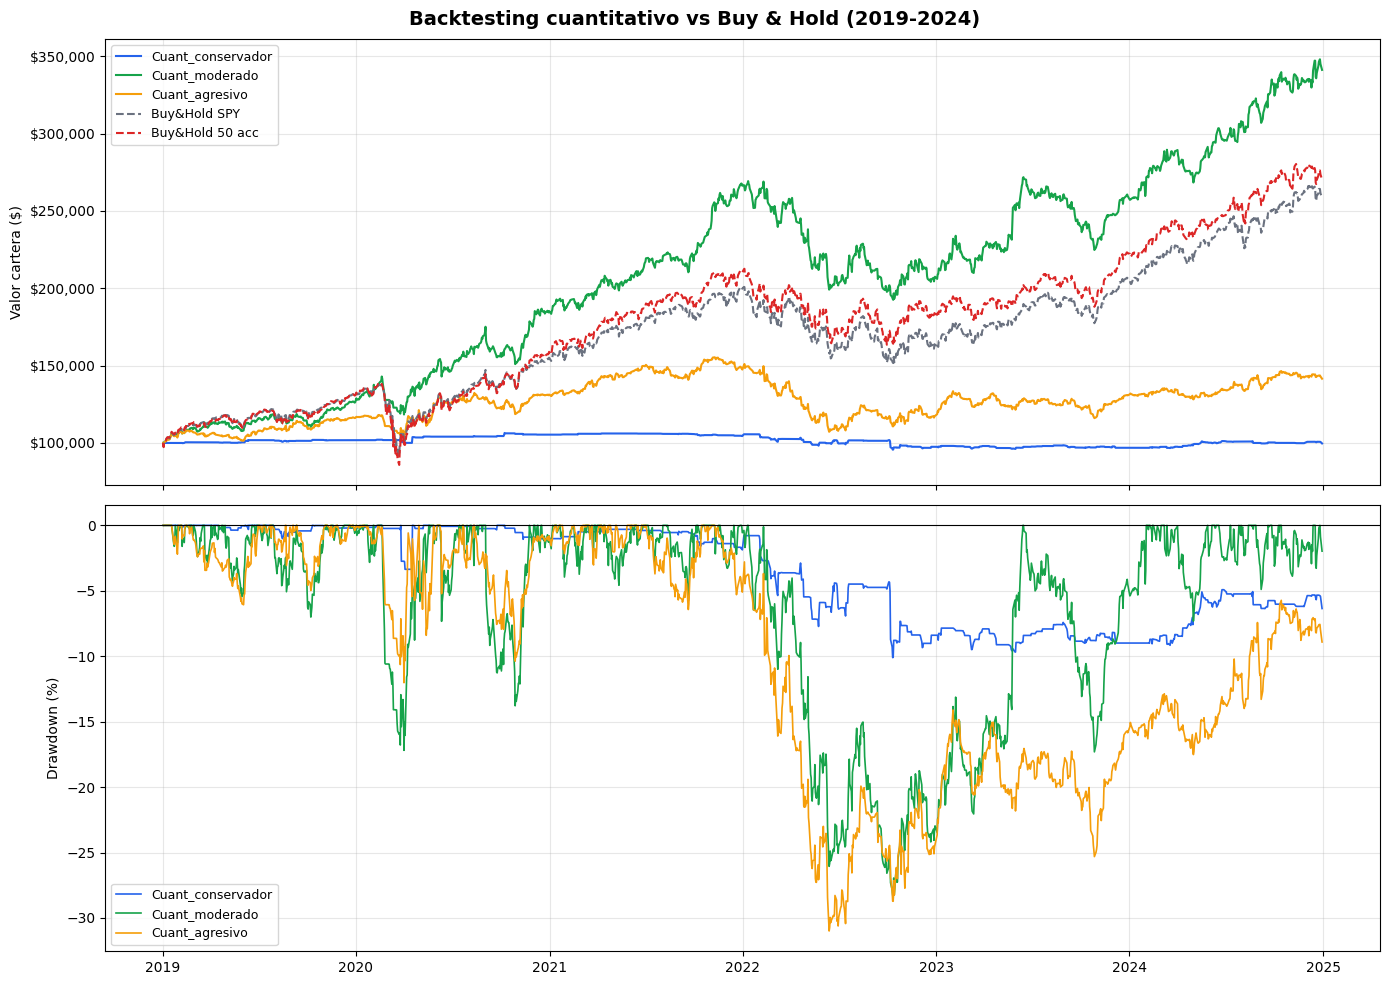


TABLA DE METRICAS COMPLETA:
                  retorno_total     CAGR volatilidad sharpe sortino max_drawdown   beta   alpha      IR
estrategia                                                                                             
Cuant_conservador        -0.32%   -0.05%       4.07%  0.007   0.005      -10.11%  0.053  -5.65%  -0.928
Cuant_moderado         +241.12%  +22.74%      17.27%  1.274   1.849      -28.50%  0.610  +9.17%   0.286
Cuant_agresivo          +41.52%   +5.97%      14.37%  0.476   0.632      -31.00%  0.493  -4.50%  -0.757
Buy&Hold SPY           +158.40%  +17.18%      19.84%  0.899   1.088      -33.72%  1.000  -0.00%   0.000


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
fig.suptitle("Backtesting cuantitativo vs Buy & Hold (2019-2024)",
             fontsize=14, fontweight="bold")

colores = {
    "Cuant_conservador": "#2563eb",
    "Cuant_moderado":    "#16a34a",
    "Cuant_agresivo":    "#f59e0b",
}

ax1 = axes[0]
for nombre, resultado in resultados_cuant.items():
    ax1.plot(resultado.index, resultado["total"],
             label=nombre, color=colores[nombre], linewidth=1.5)
ax1.plot(bh_spy.index, bh_spy, label="Buy&Hold SPY",
         color="#6b7280", linewidth=1.5, linestyle="--")
ax1.plot(bh_cartera.index, bh_cartera, label="Buy&Hold 50 acc",
         color="#dc2626", linewidth=1.5, linestyle="--")
ax1.set_ylabel("Valor cartera ($)")
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))

ax2 = axes[1]
for nombre, resultado in resultados_cuant.items():
    rolling_max = resultado["total"].cummax()
    drawdown    = ((resultado["total"] - rolling_max) / rolling_max) * 100
    ax2.plot(drawdown.index, drawdown.values,
             label=nombre, color=colores[nombre], linewidth=1.2)
ax2.set_ylabel("Drawdown (%)")
ax2.axhline(0, color="black", linewidth=0.8)
ax2.legend(fontsize=9)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/backtesting_cuantitativo.png", dpi=150, bbox_inches="tight")
plt.show()

print("\nTABLA DE METRICAS COMPLETA:")
print("="*100)
metricas_todas = []
for nombre, resultado in resultados_cuant.items():
    metricas_todas.append(calcular_metricas(resultado, nombre, bh_spy))
bh_spy_df = pd.DataFrame({"total": bh_spy}).reindex(list(resultados_cuant.values())[0].index).ffill()
metricas_todas.append(calcular_metricas(bh_spy_df, "Buy&Hold SPY", bh_spy))
df_metricas = pd.DataFrame(metricas_todas).set_index("estrategia")
print(df_metricas.to_string())

In [6]:
print("Descargando datos 2010-2018 para entrenamiento RF...")

datos_train_rf = {}
for ticker in TICKERS:
    ruta = f"../datos/{ticker}_train.parquet"
    if os.path.exists(ruta):
        datos_train_rf[ticker] = pd.read_parquet(ruta)
    else:
        try:
            df = yf.download(ticker, start="2010-01-01", end="2018-12-31",
                             progress=False, auto_adjust=True)
            if not df.empty:
                df.columns = [col[0] for col in df.columns]
                df.to_parquet(ruta)
                datos_train_rf[ticker] = df
        except Exception as e:
            print(f"Error {ticker}: {e}")

print(f"Tickers cargados    : {len(datos_train_rf)}/50")
print(f"Periodo entrenamiento: 2010-2018")
print(f"Periodo test         : 2019-2024")
print(f"\nEjemplo AAPL train — ultimas 3 filas:")
print(datos_train_rf["AAPL"].tail(3))

Descargando datos 2010-2018 para entrenamiento RF...
Tickers cargados    : 50/50
Periodo entrenamiento: 2010-2018
Periodo test         : 2019-2024

Ejemplo AAPL train — ultimas 3 filas:
                Close       High        Low       Open     Volume
Date                                                             
2018-12-26  37.325607  37.339856  34.843884  35.219111  234330000
2018-12-27  37.083363  37.230606  35.639454  37.009743  212468400
2018-12-28  37.102379  37.646223  36.703405  37.403987  169165600


In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
import joblib
import os

RUTA_MODELO   = "../results/modelo_rf_final.pkl"
RUTA_DATASET  = "../results/dataset_rf.parquet"

def construir_dataset_rf(datos_dict):
    registros = []
    for ticker in TICKERS:
        if ticker not in datos_dict:
            continue
        df = datos_dict[ticker].copy()
        delta    = df["Close"].diff()
        ganancia = delta.clip(lower=0).rolling(14).mean()
        perdida  = (-delta.clip(upper=0)).rolling(14).mean()
        rsi      = 100 - (100 / (1 + ganancia / perdida))
        ema12       = df["Close"].ewm(span=12, adjust=False).mean()
        ema26       = df["Close"].ewm(span=26, adjust=False).mean()
        macd        = ema12 - ema26
        macd_signal = macd.ewm(span=9, adjust=False).mean()
        macd_hist   = macd - macd_signal
        sma20    = df["Close"].rolling(20).mean()
        std20    = df["Close"].rolling(20).std()
        bb_upper = sma20 + 2 * std20
        bb_lower = sma20 - 2 * std20
        bb_pct   = (df["Close"] - bb_lower) / (bb_upper - bb_lower)
        sma50    = df["Close"].rolling(50).mean()
        sma200   = df["Close"].rolling(200).mean()
        retornos = df["Close"].pct_change()
        vol      = retornos.rolling(20).std() * np.sqrt(252)
        retorno_futuro = df["Close"].shift(-20) / df["Close"] - 1
        etiqueta = pd.Series(0, index=df.index)
        etiqueta[retorno_futuro >  0.05] =  1
        etiqueta[retorno_futuro < -0.05] = -1
        for fecha in df.index[200:-20]:
            registros.append({
                "ticker":      ticker,
                "fecha":       fecha,
                "rsi":         float(rsi.loc[fecha]),
                "macd":        float(macd.loc[fecha]),
                "macd_signal": float(macd_signal.loc[fecha]),
                "macd_hist":   float(macd_hist.loc[fecha]),
                "bb_pct":      float(bb_pct.loc[fecha]),
                "sma20":       float(sma20.loc[fecha]),
                "sma50":       float(sma50.loc[fecha]),
                "sma200":      float(sma200.loc[fecha]),
                "volatilidad": float(vol.loc[fecha]),
                "retorno_1d":  float(retornos.loc[fecha]),
                "etiqueta":    int(etiqueta.loc[fecha]),
            })
    return pd.DataFrame(registros)

features = ["rsi", "macd", "macd_signal", "macd_hist",
            "bb_pct", "sma20", "sma50", "sma200",
            "volatilidad", "retorno_1d"]

# ── Dataset ────────────────────────────────────────────────
if os.path.exists(RUTA_DATASET):
    print("Dataset ya existe, cargando desde disco...")
    dataset_train = pd.read_parquet(RUTA_DATASET.replace(".parquet", "_train.parquet"))
    dataset_test  = pd.read_parquet(RUTA_DATASET.replace(".parquet", "_test.parquet"))
    print(f"Train: {len(dataset_train)} filas | Test: {len(dataset_test)} filas")
else:
    print("Construyendo dataset de entrenamiento (2010-2018)...")
    dataset_train = construir_dataset_rf(datos_train_rf)
    print(f"Train: {len(dataset_train)} filas")
    print("Construyendo dataset de test (2019-2024)...")
    dataset_test = construir_dataset_rf(datos)
    print(f"Test : {len(dataset_test)} filas")
    dataset_train.to_parquet(RUTA_DATASET.replace(".parquet", "_train.parquet"), index=False)
    dataset_test.to_parquet(RUTA_DATASET.replace(".parquet", "_test.parquet"),  index=False)
    print("Datasets guardados en disco.")

X_train = dataset_train[features]
y_train = dataset_train["etiqueta"]
X_test  = dataset_test[features]
y_test  = dataset_test["etiqueta"]

# Modelo
if os.path.exists(RUTA_MODELO):
    print("\nModelo ya entrenado, cargando desde disco...")
    rf_opt = joblib.load(RUTA_MODELO)
else:
    print("\nBuscando hiperparametros optimos con GridSearchCV...")
    param_grid = {
        "n_estimators":     [100, 200],
        "max_depth":        [3, 5, 8],
        "min_samples_leaf": [100, 200, 500],
        "max_features":     [0.3, 0.5, 0.7],
    }
    tscv = TimeSeriesSplit(n_splits=5)
    grid_search = GridSearchCV(
        RandomForestClassifier(random_state=42, n_jobs=-1),
        param_grid, cv=tscv, scoring="f1_macro", n_jobs=-1, verbose=1
    )
    grid_search.fit(X_train, y_train)
    rf_opt = grid_search.best_estimator_
    print(f"\nMejores hiperparametros: {grid_search.best_params_}")
    joblib.dump(rf_opt, RUTA_MODELO)
    print(f"Modelo guardado en {RUTA_MODELO}")

#Evaluación
y_pred    = rf_opt.predict(X_test)
acc_train = rf_opt.score(X_train, y_train)
acc_test  = rf_opt.score(X_test, y_test)

print(f"\nAccuracy train (2010-2018): {acc_train:.4f}")
print(f"Accuracy test  (2019-2024): {acc_test:.4f}")
print(f"Diferencia                : {(acc_train-acc_test)*100:.2f} puntos")

if acc_train - acc_test > 0.10:
    print("ALERTA: posible overfitting (domain shift entre 2010-2018 y 2019-2024)")
else:
    print("Sin overfitting significativo")

print("\nReporte de clasificacion:")
print(classification_report(y_test, y_pred, target_names=["SELL (-1)", "HOLD (0)", "BUY (1)"]))

Construyendo dataset de entrenamiento (2010-2018)...
Train: 100453 filas
Construyendo dataset de test (2019-2024)...
Test : 64450 filas
Datasets guardados en disco.

Modelo ya entrenado, cargando desde disco...

Accuracy train (2010-2018): 0.6217
Accuracy test  (2019-2024): 0.4690
Diferencia                : 15.27 puntos
ALERTA: posible overfitting (domain shift entre 2010-2018 y 2019-2024)

Reporte de clasificacion:
              precision    recall  f1-score   support

   SELL (-1)       0.18      0.03      0.05     13443
    HOLD (0)       0.48      0.93      0.64     30260
     BUY (1)       0.40      0.08      0.13     20747

    accuracy                           0.47     64450
   macro avg       0.36      0.35      0.27     64450
weighted avg       0.39      0.47      0.35     64450



In [18]:
import os

RUTA_SENALES_RF = "../results/senales_rf_opt.parquet"
RUTA_RESULTADOS_RF = "../results/resultados_rf_opt.pkl"

# Señales RF 
if os.path.exists(RUTA_SENALES_RF):
    print("Señales RF ya generadas, cargando desde disco...")
    señales_rf_opt = pd.read_parquet(RUTA_SENALES_RF)
else:
    print("Generando señales RF para 2019-2024...")
    dataset_test_pred = dataset_test.copy()
    dataset_test_pred["prediccion"] = y_pred
    señales_rf_opt = pd.DataFrame(0, index=precios.index, columns=TICKERS)
    for _, fila in dataset_test_pred.iterrows():
        if fila["fecha"] in señales_rf_opt.index and fila["ticker"] in señales_rf_opt.columns:
            señales_rf_opt.loc[fila["fecha"], fila["ticker"]] = fila["prediccion"]
    señales_rf_opt.to_parquet(RUTA_SENALES_RF)
    print("Señales guardadas en disco.")

# Backtesting 
if os.path.exists(RUTA_RESULTADOS_RF):
    print("Resultados RF ya calculados, cargando desde disco...")
    resultados_rf_opt = joblib.load(RUTA_RESULTADOS_RF)
else:
    print("Ejecutando backtesting RF optimizado (2019-2024)...")
    resultados_rf_opt = {}
    for modo in ["conservador", "moderado", "agresivo"]:
        print(f"  Perfil {modo}...")
        resultado = backtesting_diario(precios, señales_rf_opt, modo, capital_inicial=100_000)
        resultados_rf_opt[f"RF_opt_{modo}"] = resultado
    joblib.dump(resultados_rf_opt, RUTA_RESULTADOS_RF)
    print("Resultados guardados en disco.")

# Métricas
print("\nResultados RF optimizado:")
for modo in ["conservador", "moderado", "agresivo"]:
    m = calcular_metricas(resultados_rf_opt[f"RF_opt_{modo}"], f"RF_opt_{modo}", bh_spy)
    print(f"  {m['estrategia']:<25}: Retorno={m['retorno_total']} Sharpe={m['sharpe']} MaxDD={m['max_drawdown']} Alpha={m['alpha']}")

retorno_spy     = ((bh_spy.iloc[-1] / 100_000) - 1) * 100
retorno_cartera = ((bh_cartera.iloc[-1] / 100_000) - 1) * 100
print(f"  {'Buy&Hold SPY':<25}: Retorno={retorno_spy:+.2f}%")
print(f"  {'Buy&Hold 50 acc':<25}: Retorno={retorno_cartera:+.2f}%")

Generando señales RF para 2019-2024...
Señales guardadas en disco.
Ejecutando backtesting RF optimizado (2019-2024)...
  Perfil conservador...
  Perfil moderado...
  Perfil agresivo...
Resultados guardados en disco.

Resultados RF optimizado:
  RF_opt_conservador       : Retorno=+105.17% Sharpe=0.757 MaxDD=-23.26% Alpha=-0.05%
  RF_opt_moderado          : Retorno=+64.13% Sharpe=0.678 MaxDD=-22.58% Alpha=-2.12%
  RF_opt_agresivo          : Retorno=+31.88% Sharpe=0.478 MaxDD=-24.28% Alpha=-4.69%
  Buy&Hold SPY             : Retorno=+158.40%
  Buy&Hold 50 acc          : Retorno=+170.25%


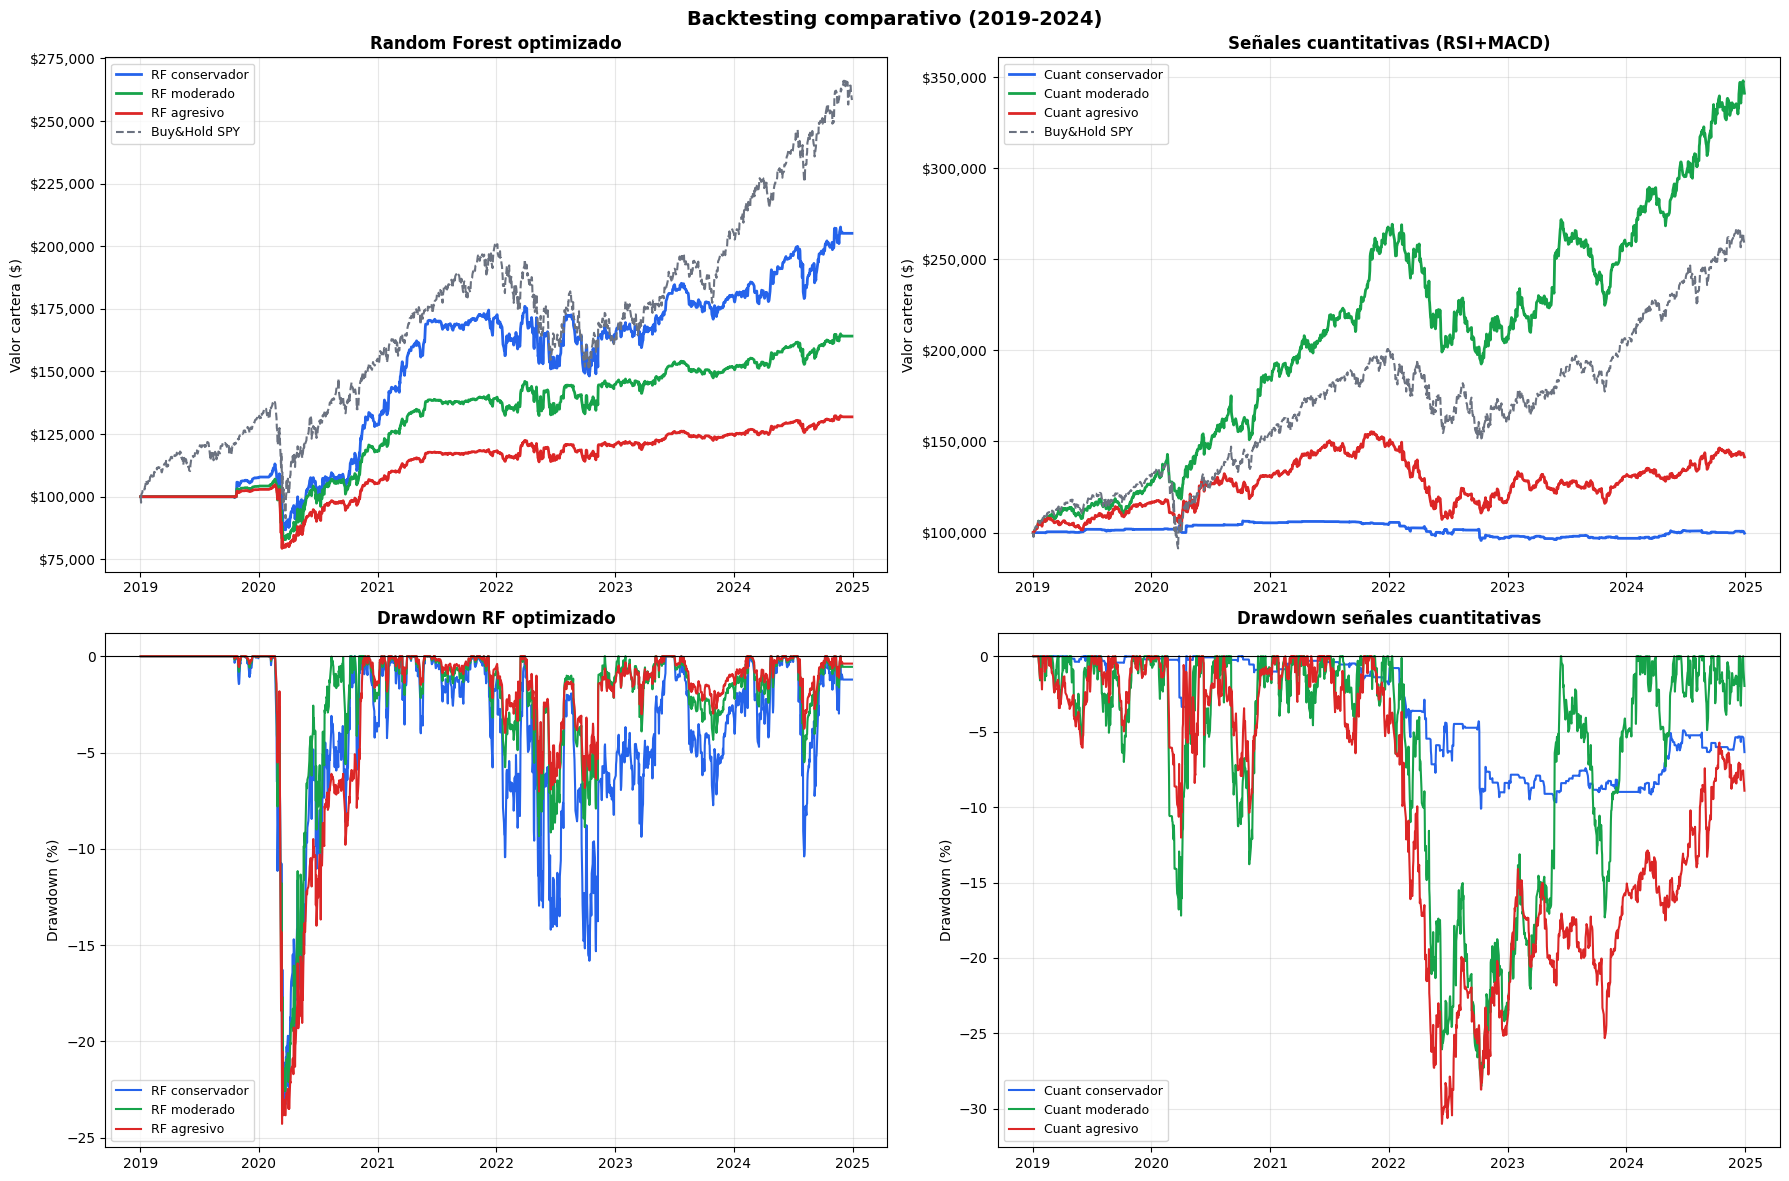

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle("Backtesting comparativo (2019-2024)", fontsize=14, fontweight="bold")

colores = {
    "conservador": "#2563eb",
    "moderado":    "#16a34a",
    "agresivo":    "#dc2626",
}

ax = axes[0, 0]
ax.set_title("Random Forest optimizado", fontweight="bold")
for modo in ["conservador", "moderado", "agresivo"]:
    r = resultados_rf_opt[f"RF_opt_{modo}"]
    ax.plot(r.index, r["total"], label=f"RF {modo}", color=colores[modo], linewidth=2)
ax.plot(bh_spy.index, bh_spy, label="Buy&Hold SPY", color="#6b7280", linewidth=1.5, linestyle="--")
ax.set_ylabel("Valor cartera ($)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))

ax = axes[0, 1]
ax.set_title("Señales cuantitativas (RSI+MACD)", fontweight="bold")
for modo in ["conservador", "moderado", "agresivo"]:
    r = resultados_cuant[f"Cuant_{modo}"]
    ax.plot(r.index, r["total"], label=f"Cuant {modo}", color=colores[modo], linewidth=2)
ax.plot(bh_spy.index, bh_spy, label="Buy&Hold SPY", color="#6b7280", linewidth=1.5, linestyle="--")
ax.set_ylabel("Valor cartera ($)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))

ax = axes[1, 0]
ax.set_title("Drawdown RF optimizado", fontweight="bold")
for modo in ["conservador", "moderado", "agresivo"]:
    r = resultados_rf_opt[f"RF_opt_{modo}"]
    rolling_max = r["total"].cummax()
    drawdown    = ((r["total"] - rolling_max) / rolling_max) * 100
    ax.plot(drawdown.index, drawdown.values, label=f"RF {modo}", color=colores[modo], linewidth=1.5)
ax.set_ylabel("Drawdown (%)")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

ax = axes[1, 1]
ax.set_title("Drawdown señales cuantitativas", fontweight="bold")
for modo in ["conservador", "moderado", "agresivo"]:
    r = resultados_cuant[f"Cuant_{modo}"]
    rolling_max = r["total"].cummax()
    drawdown    = ((r["total"] - rolling_max) / rolling_max) * 100
    ax.plot(drawdown.index, drawdown.values, label=f"Cuant {modo}", color=colores[modo], linewidth=1.5)
ax.set_ylabel("Drawdown (%)")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/backtesting_comparativo.png", dpi=150, bbox_inches="tight")
plt.show()

[conservador] Meses procesados: 72/72
[conservador] Señales totales : 3600
[moderado] Meses procesados: 72/72
[moderado] Señales totales : 3600
[agresivo] Meses procesados: 72/72
[agresivo] Señales totales : 3600

TABLA COMPARATIVA FINAL:
                  retorno_total     CAGR volatilidad sharpe sortino max_drawdown   beta   alpha      IR
estrategia                                                                                             
Cuant_conservador        -0.32%   -0.05%       4.07%  0.007   0.005      -10.11%  0.053  -5.65%  -0.928
Cuant_moderado         +241.12%  +22.74%      17.27%  1.274   1.849      -28.50%  0.610  +9.17%   0.286
Cuant_agresivo          +41.52%   +5.97%      14.37%  0.476   0.632      -31.00%  0.493  -4.50%  -0.757
RF_conservador         +105.17%  +12.75%      18.01%  0.757   0.855      -23.26%  0.676  -0.05%  -0.309
RF_moderado             +64.13%   +8.63%      13.58%  0.678   0.709      -22.58%  0.493  -2.12%  -0.627
RF_agresivo             +31.88%  

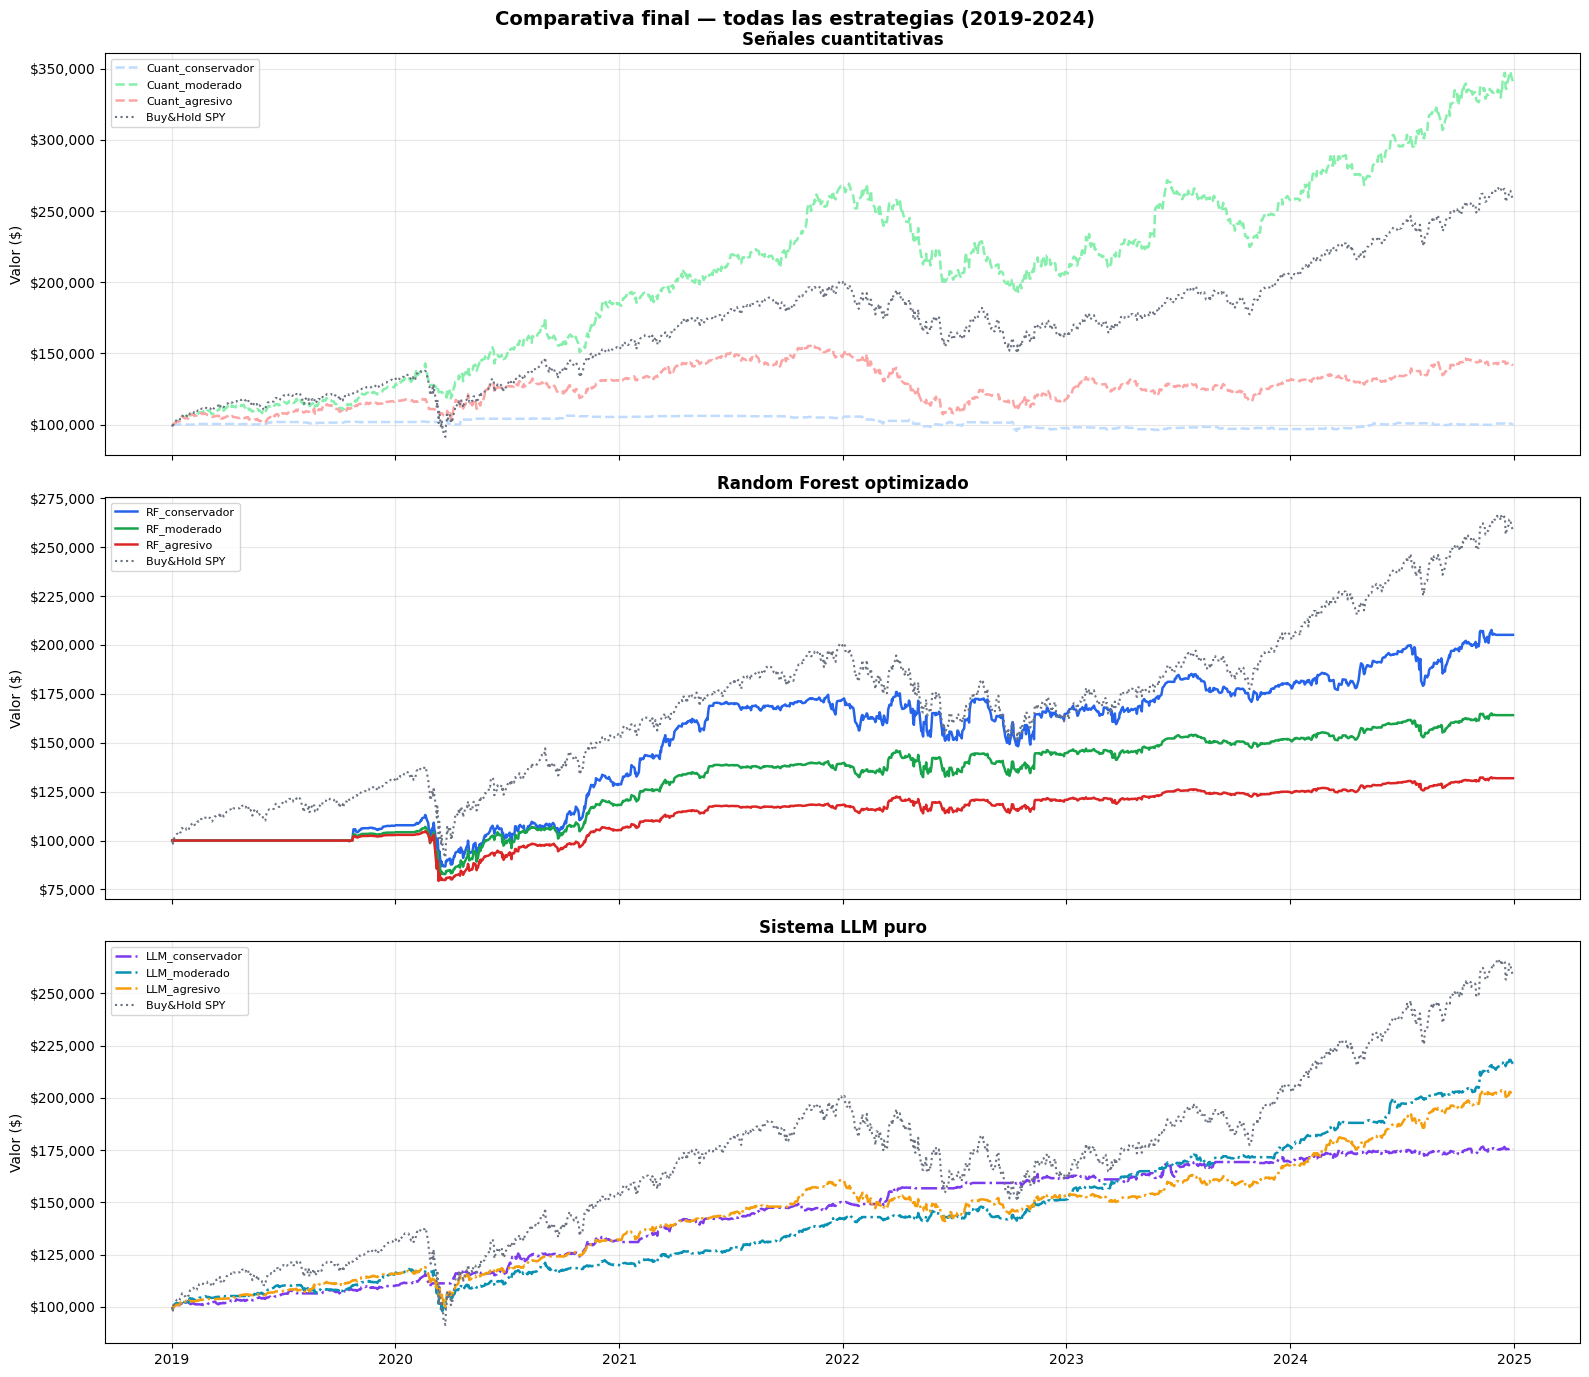

In [21]:
def backtesting_llm(perfil, capital_inicial=100_000):
    ruta_csv = f"../results/señales_mensuales_{perfil}.csv"

    if not os.path.exists(ruta_csv):
        print(f"No existe el archivo {ruta_csv}")
        print(f"Ejecuta primero: generar_señales_mensuales(datos, llm, perfiles=['{perfil}'])")
        return None

    señales_df = pd.read_csv(ruta_csv)
    señales_df["fecha"] = pd.to_datetime(señales_df["fecha"])

    meses_procesados = señales_df.groupby(["año", "mes"]).size()
    print(f"[{perfil}] Meses procesados: {len(meses_procesados)}/72")
    print(f"[{perfil}] Señales totales : {len(señales_df)}")

    if len(meses_procesados) < 72:
        print(f"AVISO: faltan {72 - len(meses_procesados)} meses por procesar")

    return backtesting(precios, señales_df, perfil, capital_inicial)


def comparativa_final():
    todas_metricas   = []
    todos_resultados = {}

    # Cuantitativo
    for modo in ["conservador", "moderado", "agresivo"]:
        nombre = f"Cuant_{modo}"
        todos_resultados[nombre] = resultados_cuant[nombre]
        todas_metricas.append(calcular_metricas(resultados_cuant[nombre], nombre, bh_spy))

    # Random Forest
    for modo in ["conservador", "moderado", "agresivo"]:
        nombre = f"RF_{modo}"
        todos_resultados[nombre] = resultados_rf_opt[f"RF_opt_{modo}"]
        todas_metricas.append(calcular_metricas(resultados_rf_opt[f"RF_opt_{modo}"], nombre, bh_spy))

    # LLM ; solo si existen los CSVs
    for modo in ["conservador", "moderado", "agresivo"]:
        ruta = f"../results/señales_mensuales_{modo}.csv"
        if os.path.exists(ruta):
            resultado_llm = backtesting_llm(modo)
            if resultado_llm is not None:
                nombre = f"LLM_{modo}"
                todos_resultados[nombre] = resultado_llm
                todas_metricas.append(calcular_metricas(resultado_llm, nombre, bh_spy))
        else:
            print(f"LLM_{modo}: CSV no disponible todavia")

    # Buy & Hold
    bh_spy_df = pd.DataFrame({"total": bh_spy}).reindex(precios.index).ffill()
    bh_50_df  = pd.DataFrame({"total": bh_cartera})
    todas_metricas.append(calcular_metricas(bh_spy_df, "Buy&Hold_SPY", bh_spy))
    todas_metricas.append(calcular_metricas(bh_50_df,  "Buy&Hold_50",  bh_spy))

    # Tabla
    df_metricas = pd.DataFrame(todas_metricas).set_index("estrategia")
    print("\nTABLA COMPARATIVA FINAL:")
    print("="*100)
    print(df_metricas.to_string())
    df_metricas.to_csv("../results/tabla_comparativa_final.csv")
    print("\nTabla guardada en ../results/tabla_comparativa_final.csv")

    # Grafico
    fig, axes = plt.subplots(3, 1, figsize=(16, 14), sharex=True)
    fig.suptitle("Comparativa final — todas las estrategias (2019-2024)",
                 fontsize=14, fontweight="bold")

    colores_estrategias = {
        "Cuant_conservador": "#bfdbfe",
        "Cuant_moderado":    "#86efac",
        "Cuant_agresivo":    "#fca5a5",
        "RF_conservador":    "#2563eb",
        "RF_moderado":       "#16a34a",
        "RF_agresivo":       "#dc2626",
        "LLM_conservador":   "#7c3aed",
        "LLM_moderado":      "#0891b2",
        "LLM_agresivo":      "#f59e0b",
    }

    ax1 = axes[0]
    ax1.set_title("Señales cuantitativas", fontweight="bold")
    for modo in ["conservador", "moderado", "agresivo"]:
        nombre = f"Cuant_{modo}"
        if nombre in todos_resultados:
            r = todos_resultados[nombre]
            ax1.plot(r.index, r["total"], label=nombre,
                     color=colores_estrategias[nombre], linewidth=1.8, linestyle="--")
    ax1.plot(bh_spy.index, bh_spy, label="Buy&Hold SPY",
             color="#6b7280", linewidth=1.5, linestyle=":")
    ax1.set_ylabel("Valor ($)")
    ax1.legend(fontsize=8)
    ax1.grid(True, alpha=0.3)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))

    ax2 = axes[1]
    ax2.set_title("Random Forest optimizado", fontweight="bold")
    for modo in ["conservador", "moderado", "agresivo"]:
        nombre = f"RF_{modo}"
        if nombre in todos_resultados:
            r = todos_resultados[nombre]
            ax2.plot(r.index, r["total"], label=nombre,
                     color=colores_estrategias[nombre], linewidth=1.8)
    ax2.plot(bh_spy.index, bh_spy, label="Buy&Hold SPY",
             color="#6b7280", linewidth=1.5, linestyle=":")
    ax2.set_ylabel("Valor ($)")
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3)
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))

    ax3 = axes[2]
    ax3.set_title("Sistema LLM puro", fontweight="bold")
    llm_disponible = False
    for modo in ["conservador", "moderado", "agresivo"]:
        nombre = f"LLM_{modo}"
        if nombre in todos_resultados:
            r = todos_resultados[nombre]
            ax3.plot(r.index, r["total"], label=nombre,
                     color=colores_estrategias[nombre], linewidth=1.8, linestyle="-.")
            llm_disponible = True
    if not llm_disponible:
        ax3.text(0.5, 0.5, "Señales LLM pendientes de generar\nEjecuta generar_señales_mensuales()",
                 ha="center", va="center", transform=ax3.transAxes,
                 fontsize=12, color="#6b7280")
    ax3.plot(bh_spy.index, bh_spy, label="Buy&Hold SPY",
             color="#6b7280", linewidth=1.5, linestyle=":")
    ax3.set_ylabel("Valor ($)")
    ax3.legend(fontsize=8)
    ax3.grid(True, alpha=0.3)
    ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))

    plt.tight_layout()
    plt.savefig("../results/comparativa_final.png", dpi=150, bbox_inches="tight")
    plt.show()

# Ejecutamos la comparativa con lo que tenemos ahora
comparativa_final()

In [24]:
# 
# CELDA PARA EJECUTAR OVERNIGHT
# 
# Tarda aproximadamente 9.5 horas para los 3 perfiles
# Guarda progresivamente en ../results/
# Si se interrumpe, retoma desde donde se quedo

# Para ejecutar los 3 perfiles completos (~9.5 horas):
#generar_señales_mensuales(datos, llm)

# Para ejecutar solo un perfil (~3.2 horas):
generar_señales_mensuales(datos, llm, perfiles=["conservador"])

# Para ver el progreso actual:
for perfil in ["moderado","conservador", "agresivo"]:
    ruta = f"../results/señales_mensuales_{perfil}.csv"
    if os.path.exists(ruta):
        df = pd.read_csv(ruta)
        meses = df.groupby(["año", "mes"]).size()
        print(f"[{perfil}] {len(meses)}/72 meses completados ({len(df)} señales)")
    else:
        print(f"[{perfil}] Sin empezar")

[conservador] Retomando desde donde se quedo — 72 meses ya procesados

[conservador] Completado en 0.0 horas

Generacion de señales mensuales completada
[moderado] 72/72 meses completados (3600 señales)
[conservador] 72/72 meses completados (3600 señales)
[agresivo] 72/72 meses completados (3600 señales)


---

## Backtesting Sistema hibrido (RF + FinBERT + Mistral orquestador)

Las celdas anteriores cubren:
- **Cuantitativo** (RSI+MACD): celdas 4-5
- **Random Forest monolítico**: celdas 6-9
- **LLM puro**: celdas 10-11

Esta sección añade el backtesting del **sistema hibrido**:
- 3 RF especializados (técnico, fundamental, riesgo)
- FinBERT para sentimiento
- Mistral solo como orquestador

Los CSVs se guardan con prefijo `v3_` con el que me refiero al sistema hibrido para no mezclarlos con los de v2 con los que me refuero al sistema LLM puro.


In [25]:
# Imports sistema hibrido 
import sys
sys.path.append("../src")

from sistema_hibrido import (
    AgentesV3,
    cargar_datos as cargar_datos_v3,
    cargar_noticias,
    TICKERS, NOMBRES, PERFILES,
)

# Reutilizar datos ya cargados en celda 1 si existen, si no recargar
try:
    _ = datos
    print("✓ Datos ya en memoria desde celda 1")
except NameError:
    datos = cargar_datos_v3()

try:
    _ = precios
    print("✓ Precios ya en memoria desde celda 1")
except NameError:
    import pandas as pd
    precios = pd.DataFrame({t: datos[t]["Close"] for t in TICKERS}).dropna()

# Cargar noticias FNSPID una sola vez
cargar_noticias()

# Inicializar sistema v3
sistema_v3 = AgentesV3()
print("\n✓ Sistema hibrido inicializado")


✓ Datos ya en memoria desde celda 1
✓ Precios ya en memoria desde celda 1
Noticias ya en memoria: 159,997 registros

✓ Sistema hibrido inicializado


In [26]:
#Entrenar RF 
# Carga desde PKL si ya existen en ../results/modelos_v3/
# Si no, GridSearchCV × 3 (~15 min la primera vez)

resultados_train_v3 = sistema_v3.entrenar(datos)

if resultados_train_v3:
    print("\n── Métricas RF v3 ──")
    for nombre, r in resultados_train_v3.items():
        print(f"  {nombre:<15} acc_train={r['acc_train']:.3f}  acc_test={r['acc_test']:.3f}  params={r['best_params']}")
else:
    print("Modelos cargados desde disco — omitiendo métricas de entrenamiento")


Cargando modelos RF v3 desde disco...
Modelos cargados.
Modelos cargados desde disco — omitiendo métricas de entrenamiento


In [27]:
# Generar señales mensuales sistema hibrido
#
# Tiempo estimado: ~2.5 min × 72 meses × 3 perfiles = ~9 horas
# Guarda CSV con checkpoint tras cada mes → se puede reanudar si se interrumpe
# CSVs: ../results/v3_señales_mensuales_{perfil}.csv
#
# Para ejecutar los 3 perfiles completos descomenta la linea de abajo:

# señales_v3_generadas = sistema_v3.generar_señales_mensuales(datos)

# Para ejecutar solo un perfil (prueba o reanudacion):
# señales_v3_generadas = sistema_v3.generar_señales_mensuales(datos, perfiles=["moderado"])

# Para ver el progreso actual:
import os, pandas as pd

print("Estado actual de señales v3:")
print("="*50)
for perfil in ["conservador", "moderado", "agresivo"]:
    ruta = f"../results/v3_señales_mensuales_{perfil}.csv"
    if os.path.exists(ruta):
        df = pd.read_csv(ruta)
        meses = df.groupby(["año", "mes"]).size()
        print(f"  [{perfil}] {len(meses):>2}/72 meses  ({len(df):>5} señales)")
    else:
        print(f"  [{perfil}]  0/72 meses  (sin empezar)")


Estado actual de señales v3:
  [conservador] 71/72 meses  ( 3550 señales)
  [moderado] 71/72 meses  ( 3550 señales)
  [agresivo] 71/72 meses  ( 3550 señales)


In [28]:
#Backtesting sistema hibrido con CSVs generados
# Ejecutar tras tener al menos un perfil completo (72 meses)

import os, pandas as pd

def backtesting_v3(perfil, capital_inicial=100_000):
    ruta = f"../results/v3_señales_mensuales_{perfil}.csv"
    if not os.path.exists(ruta):
        print(f"  [{perfil}] CSV no encontrado: {ruta}")
        return None

    señales_df = pd.read_csv(ruta)
    # Filtrar solo tickers validos (evitar alucinaciones del LLM)
    señales_df = señales_df[señales_df["ticker"].isin(TICKERS)]
    señales_df["fecha"] = pd.to_datetime(señales_df["fecha"])

    meses_procesados = señales_df.groupby(["año", "mes"]).size()
    print(f"  [{perfil}] {len(meses_procesados)}/72 meses | {len(señales_df)} señales")
    if len(meses_procesados) < 72:
        print(f"  [{perfil}] AVISO: faltan {72 - len(meses_procesados)} meses")

    # Reutilizar funcion backtesting() definida en celda 3
    return backtesting(precios, señales_df, perfil, capital_inicial)

print("Ejecutando backtesting sistema hibrido...")
resultados_v3 = {}

for modo in ["conservador", "moderado", "agresivo"]:
    resultado = backtesting_v3(modo)
    if resultado is not None:
        resultados_v3[f"v3_{modo}"] = resultado
        m = calcular_metricas(resultado, f"v3_{modo}", bh_spy)
        print(f"  {m['estrategia']:<20}: Retorno={m['retorno_total']} "
              f"Sharpe={m['sharpe']} MaxDD={m['max_drawdown']} Alpha={m['alpha']}")

if not resultados_v3:
    print("\nNo hay resultados sistema hibrido disponibles todavia.")
    print("Ejecuta la celda 14 (overnight) para generar las señales.")


Ejecutando backtesting v3...
  [conservador] 71/72 meses | 3550 señales
  [conservador] AVISO: faltan 1 meses
  v3_conservador      : Retorno=+16.02% Sharpe=0.474 MaxDD=-8.32% Alpha=-4.13%
  [moderado] 71/72 meses | 3550 señales
  [moderado] AVISO: faltan 1 meses
  v3_moderado         : Retorno=+120.09% Sharpe=0.957 MaxDD=-21.33% Alpha=+0.95%
  [agresivo] 71/72 meses | 3550 señales
  [agresivo] AVISO: faltan 1 meses
  v3_agresivo         : Retorno=+334.23% Sharpe=1.256 MaxDD=-31.18% Alpha=+10.73%


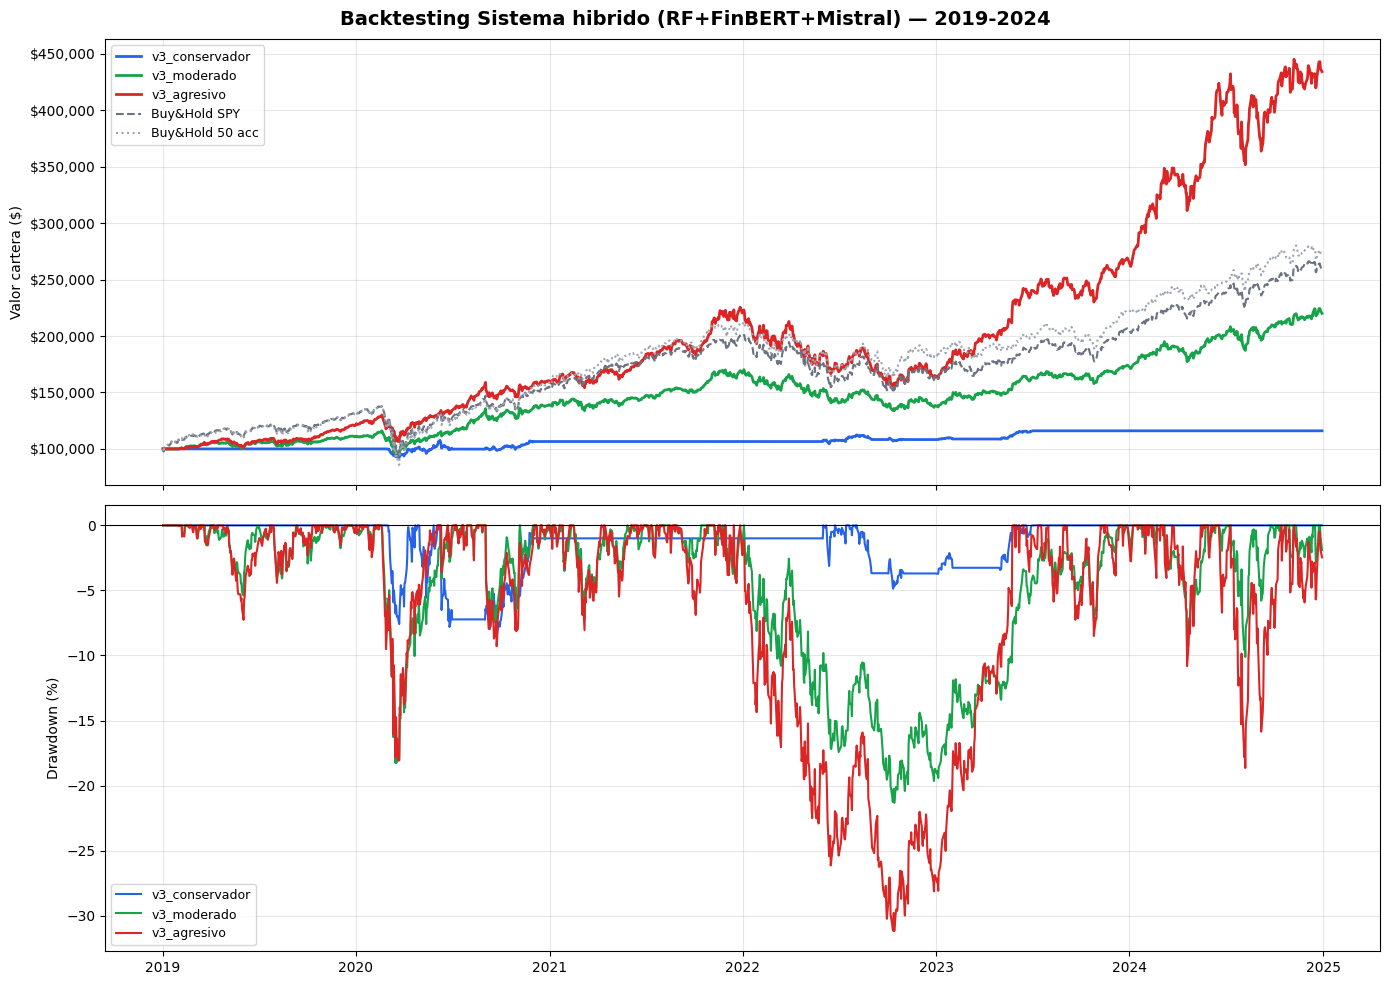

Gráfico guardado en ../results/backtesting_v3.png


In [36]:
#  Visualizacion sistema hibrido 
import matplotlib.pyplot as plt

if not resultados_v3:
    print("Sin resultados sistema hibrido. Ejecuta celda 14 primero.")
else:
    fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
    fig.suptitle("Backtesting Sistema hibrido (RF+FinBERT+Mistral) — 2019-2024",
                 fontsize=14, fontweight="bold")

    colores = {
        "v3_conservador": "#2563eb",
        "v3_moderado":    "#16a34a",
        "v3_agresivo":    "#dc2626",
    }

    ax1 = axes[0]
    for nombre, resultado in resultados_v3.items():
        ax1.plot(resultado.index, resultado["total"],
                 label=nombre, color=colores[nombre], linewidth=2)
    ax1.plot(bh_spy.index, bh_spy, label="Buy&Hold SPY",
             color="#6b7280", linewidth=1.5, linestyle="--")
    ax1.plot(bh_cartera.index, bh_cartera, label="Buy&Hold 50 acc",
             color="#9ca3af", linewidth=1.5, linestyle=":")
    ax1.set_ylabel("Valor cartera ($)")
    ax1.legend(fontsize=9)
    ax1.grid(True, alpha=0.3)
    ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))

    ax2 = axes[1]
    for nombre, resultado in resultados_v3.items():
        rolling_max = resultado["total"].cummax()
        drawdown    = ((resultado["total"] - rolling_max) / rolling_max) * 100
        ax2.plot(drawdown.index, drawdown.values,
                 label=nombre, color=colores[nombre], linewidth=1.5)
    ax2.set_ylabel("Drawdown (%)")
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.legend(fontsize=9)
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("../results/backtesting_v3.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Gráfico guardado en ../results/backtesting_v3.png")



TABLA COMPARATIVA FINAL — todas las estrategias:
                  retorno_total     CAGR volatilidad sharpe sortino max_drawdown   beta    alpha      IR
estrategia                                                                                              
Cuant_conservador        -0.32%   -0.05%       4.07%  0.007   0.005      -10.11%  0.053   -5.65%  -0.928
Cuant_moderado         +241.12%  +22.74%      17.27%  1.274   1.849      -28.50%  0.610   +9.17%   0.286
Cuant_agresivo          +41.52%   +5.97%      14.37%  0.476   0.632      -31.00%  0.493   -4.50%  -0.757
RF_conservador         +105.17%  +12.75%      18.01%  0.757   0.855      -23.26%  0.676   -0.05%  -0.309
RF_moderado             +64.13%   +8.63%      13.58%  0.678   0.709      -22.58%  0.493   -2.12%  -0.627
RF_agresivo             +31.88%   +4.73%      10.96%  0.478   0.440      -24.28%  0.384   -4.69%  -0.866
LLMv2_conservador       +75.45%   +9.84%       5.75%  1.663   2.160       -4.98%  0.120   +3.03%  -0.454
LLMv2

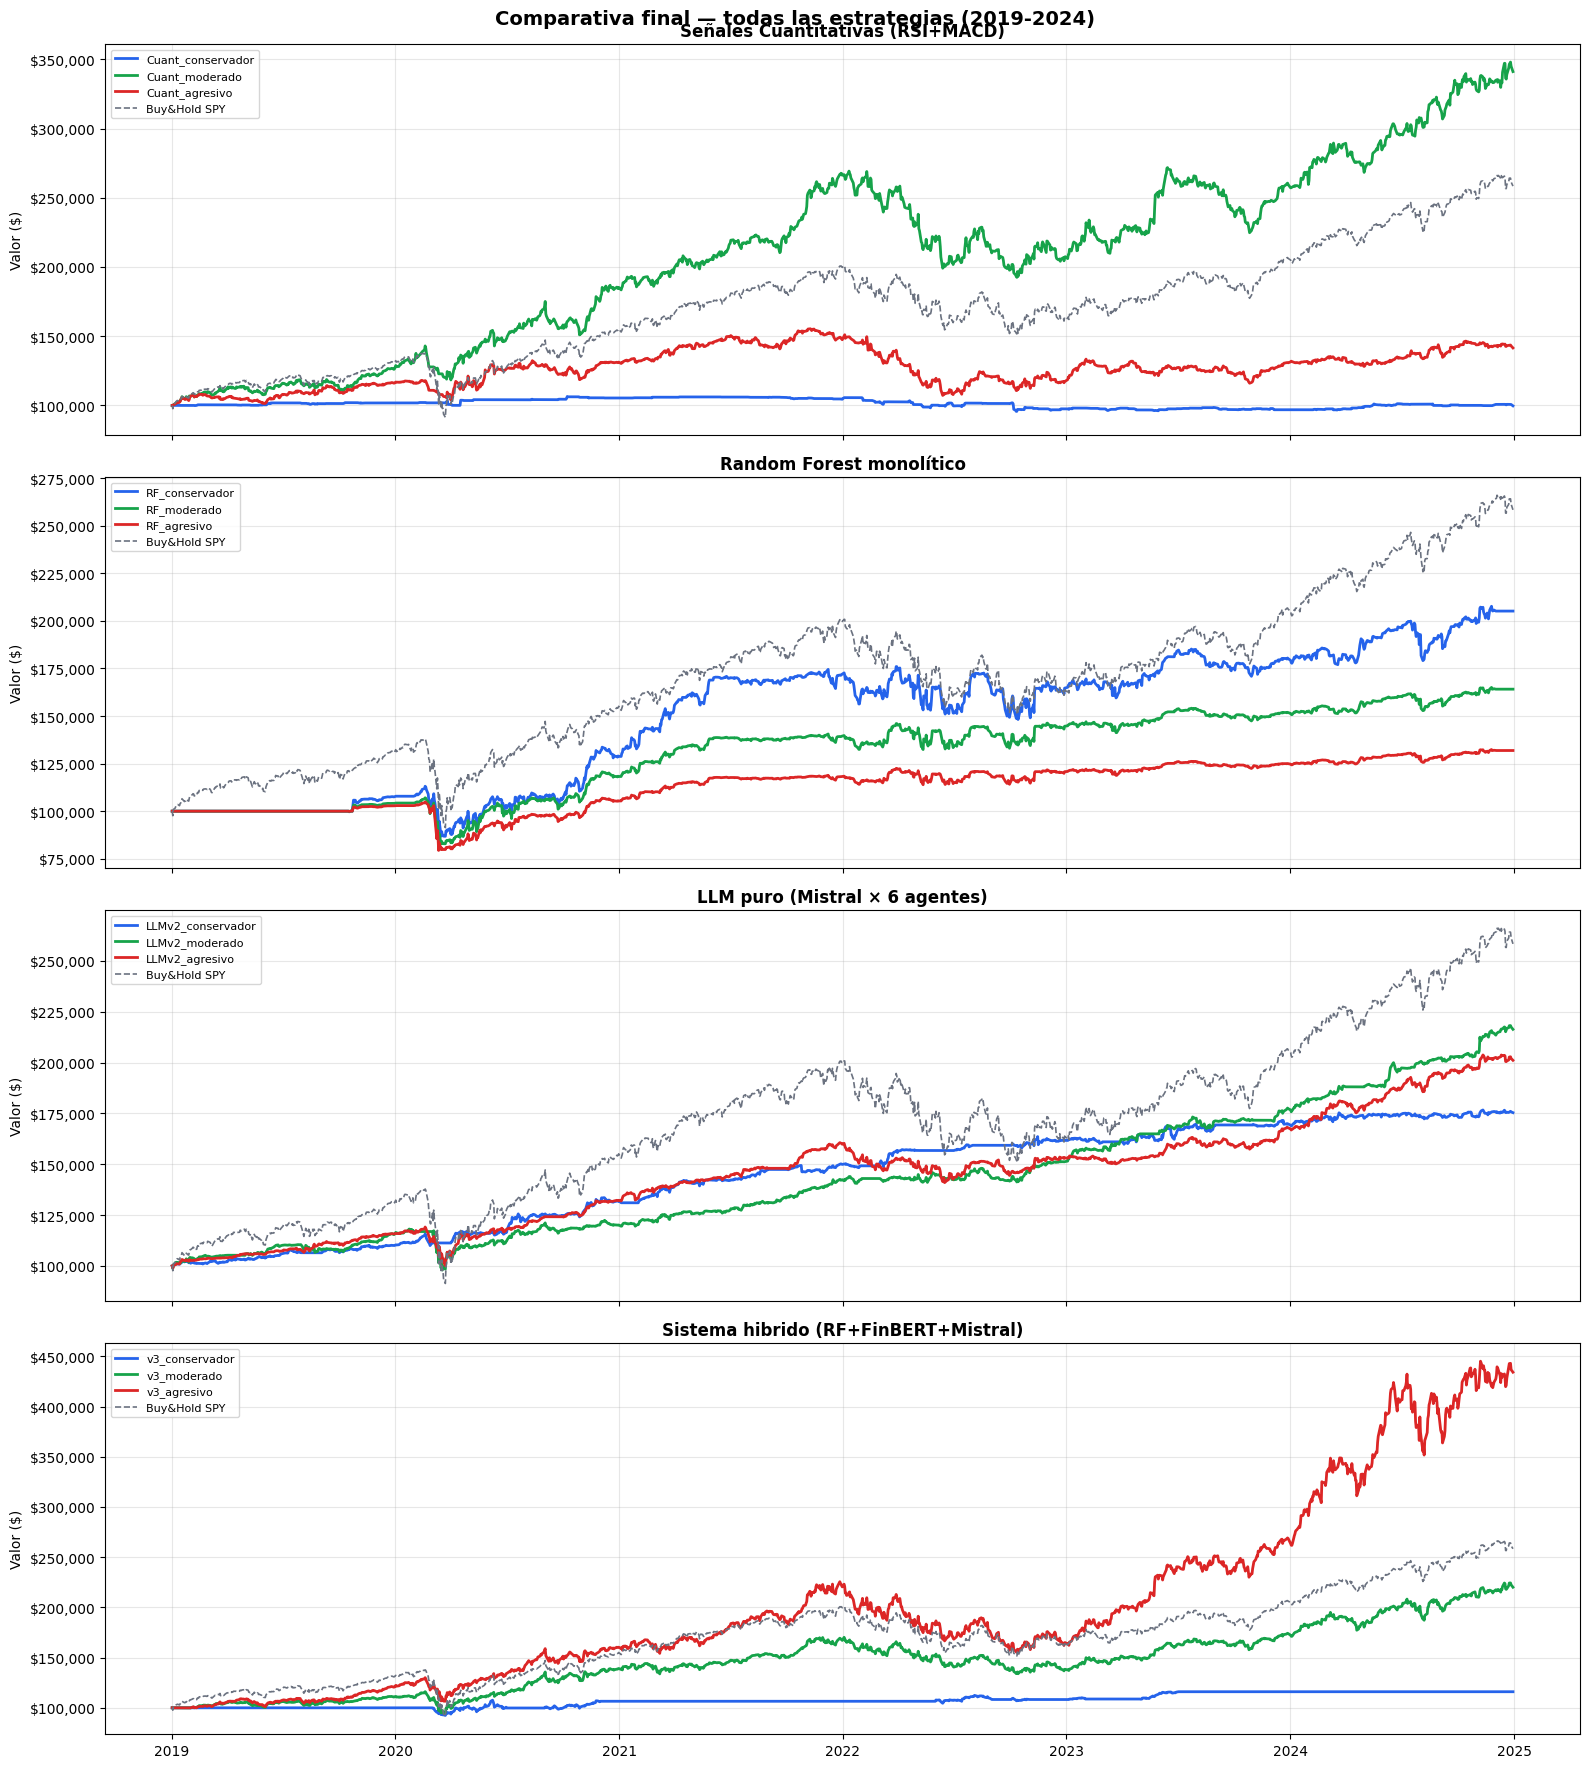

Gráfico guardado en ../results/comparativa_final_completa.png


In [31]:
# Comparativa final: todas las estrategias 
# Combina cuantitativo + RF monolitico + LLM puro + sistema hibrido

def comparativa_final_completa():
    todas_metricas   = []
    todos_resultados = {}

    #Cuantitativo 
    for modo in ["conservador", "moderado", "agresivo"]:
        nombre = f"Cuant_{modo}"
        if nombre in resultados_cuant:
            todos_resultados[nombre] = resultados_cuant[nombre]
            todas_metricas.append(calcular_metricas(resultados_cuant[nombre], nombre, bh_spy))

    # RF monolitico 
    for modo in ["conservador", "moderado", "agresivo"]:
        nombre_key  = f"RF_opt_{modo}"
        nombre_show = f"RF_{modo}"
        if nombre_key in resultados_rf_opt:
            todos_resultados[nombre_show] = resultados_rf_opt[nombre_key]
            todas_metricas.append(calcular_metricas(resultados_rf_opt[nombre_key], nombre_show, bh_spy))

    # LLM puro 
    for modo in ["conservador", "moderado", "agresivo"]:
        ruta = f"../results/señales_mensuales_{modo}.csv"
        if os.path.exists(ruta):
            df_llm = pd.read_csv(ruta)
            df_llm["fecha"] = pd.to_datetime(df_llm["fecha"])
            res = backtesting(precios, df_llm, modo, 100_000)
            if res is not None:
                nombre = f"LLMv2_{modo}"
                todos_resultados[nombre] = res
                todas_metricas.append(calcular_metricas(res, nombre, bh_spy))
        else:
            print(f"  LLMv2_{modo}: CSV no disponible")

    # Sistema hibrido
    for modo in ["conservador", "moderado", "agresivo"]:
        nombre = f"v3_{modo}"
        if nombre in resultados_v3:
            todos_resultados[nombre] = resultados_v3[nombre]
            todas_metricas.append(calcular_metricas(resultados_v3[nombre], nombre, bh_spy))
        else:
            print(f"  v3_{modo}: sin resultados todavia")

    # Buy & Hold
    bh_spy_df = pd.DataFrame({"total": bh_spy}).reindex(precios.index).ffill()
    bh_50_df  = pd.DataFrame({"total": bh_cartera})
    todas_metricas.append(calcular_metricas(bh_spy_df, "BuyHold_SPY", bh_spy))
    todas_metricas.append(calcular_metricas(bh_50_df,  "BuyHold_50",  bh_spy))

    # Tabla
    df_metricas = pd.DataFrame(todas_metricas).set_index("estrategia")
    print("\nTABLA COMPARATIVA FINAL — todas las estrategias:")
    print("="*110)
    print(df_metricas.to_string())
    df_metricas.to_csv("../results/tabla_comparativa_final_v3.csv")
    print("\nTabla guardada en ../results/tabla_comparativa_final_v3.csv")

    # Grafico comparativo
    if len(todos_resultados) < 2:
        print("Pocas estrategias disponibles para grafico comparativo.")
        return df_metricas

    fig, axes = plt.subplots(4, 1, figsize=(16, 18), sharex=True)
    fig.suptitle("Comparativa final — todas las estrategias (2019-2024)",
                 fontsize=14, fontweight="bold")

    grupos = {
        "Señales Cuantitativas (RSI+MACD)": {
            k: v for k, v in todos_resultados.items() if k.startswith("Cuant")
        },
        "Random Forest monolítico": {
            k: v for k, v in todos_resultados.items() if k.startswith("RF_")
        },
        "LLM v2 (Mistral × 6 agentes)": {
            k: v for k, v in todos_resultados.items() if k.startswith("LLMv2")
        },
        "Sistema hibrido (RF+FinBERT+Mistral)": {
            k: v for k, v in todos_resultados.items() if k.startswith("v3_")
        },
    }

    colores_perfil = {
        "conservador": "#2563eb",
        "moderado":    "#16a34a",
        "agresivo":    "#dc2626",
    }

    for ax, (titulo, grupo) in zip(axes, grupos.items()):
        ax.set_title(titulo, fontweight="bold")
        for nombre, resultado in grupo.items():
            perfil  = nombre.split("_")[-1]
            color   = colores_perfil.get(perfil, "#6b7280")
            ax.plot(resultado.index, resultado["total"],
                    label=nombre, color=color, linewidth=2)
        ax.plot(bh_spy.index, bh_spy, label="Buy&Hold SPY",
                color="#6b7280", linewidth=1.2, linestyle="--")
        ax.set_ylabel("Valor ($)")
        ax.legend(fontsize=8)
        ax.grid(True, alpha=0.3)
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))

    plt.tight_layout()
    plt.savefig("../results/comparativa_final_completa.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Gráfico guardado en ../results/comparativa_final_completa.png")

    return df_metricas

df_comparativa = comparativa_final_completa()


In [32]:
# Overnight sistema hibrido
# Descomenta el perfil que quieras ejecutar
# ~2.5 min × 72 meses = ~3 horas por perfil
# Checkpoint automático: si se interrumpe, retoma desde donde se quedo

# Los 3 perfiles completos (~9 horas):
señales_v3_generadas = sistema_v3.generar_señales_mensuales(datos)

# Solo moderado (~3 horas, recomendado para empezar):
# señales_v3_generadas = sistema_v3.generar_señales_mensuales(datos, perfiles=["moderado"])

# Solo conservador:
# señales_v3_generadas = sistema_v3.generar_señales_mensuales(datos, perfiles=["conservador"])

# Solo agresivo:
# señales_v3_generadas = sistema_v3.generar_señales_mensuales(datos, perfiles=["agresivo"])

# ── Monitor de progreso (ejecutar en celda separada mientras corre overnight) ──
import os, pandas as pd, time

def ver_progreso_v3():
    print(f"Estado sistema hibrido — {pd.Timestamp.now().strftime('%H:%M:%S')}")
    print("="*50)
    for perfil in ["conservador", "moderado", "agresivo"]:
        ruta = f"../results/v3_señales_mensuales_{perfil}.csv"
        if os.path.exists(ruta):
            df = pd.read_csv(ruta)
            meses = df.groupby(["año", "mes"]).size()
            ultimo = df.tail(1)[["año","mes"]].values[0] if len(df) > 0 else ["?","?"]
            print(f"  [{perfil}] {len(meses):>2}/72 meses | ultimo: {ultimo[0]}-{ultimo[1]:02}")
        else:
            print(f"  [{perfil}]  0/72 meses")

ver_progreso_v3()


Noticias ya en memoria: 159,997 registros
[v3/conservador] Reanudando: 71/72 meses

[v3/conservador] 2019-01 [ERR AAPL:"None of [Index(['rsi', 'macd', 'macd_signal', 'macd_hist', 'bb_pct', 'sma20_ratio',\n       'sma50_ratio', 'sma200_ratio', 'retorno_1d', 'retorno_5d'],\n      dtype='object')] are in the [columns]"] [ERR MSFT:"None of [Index(['rsi', 'macd', 'macd_signal', 'macd_hist', 'bb_pct', 'sma20_ratio',\n       'sma50_ratio', 'sma200_ratio', 'retorno_1d', 'retorno_5d'],\n      dtype='object')] are in the [columns]"] [ERR NVDA:"None of [Index(['rsi', 'macd', 'macd_signal', 'macd_hist', 'bb_pct', 'sma20_ratio',\n       'sma50_ratio', 'sma200_ratio', 'retorno_1d', 'retorno_5d'],\n      dtype='object')] are in the [columns]"] [ERR GOOGL:"None of [Index(['rsi', 'macd', 'macd_signal', 'macd_hist', 'bb_pct', 'sma20_ratio',\n       'sma50_ratio', 'sma200_ratio', 'retorno_1d', 'retorno_5d'],\n      dtype='object')] are in the [columns]"] [ERR META:"None of [Index(['rsi', 'macd', 'macd_si